# Value functions and the backward builders

<div class="alert alert-info">

**Summary**

This lesson constructs the consumption stage of the portfolio–consumption model and reads the operators that compute its value functions. You will read the value at each perch and open the two [[backward_builder|backward builders]] that compute the values, from continuation to decision and from decision to arrival: the operations each composes, the kernels of its pullback and its aggregation, and the derivative of the decision value that the file states. The lesson constructs; it binds no parameter value, and nothing is evaluated or solved.

</div>

<div class="alert alert-success">

**Relationship with other documents**

**Builds on** — [The stage as an object](01-the-stage.ipynb): the stage, its builders and their cards.

**Formal account** — [Stages and perches](../../docs/bellman-calculus/03-Stages%20and%20perches.md): the backward recursion of a stage.

**Used by** — [Distributions and the forward builders](03-distributions.ipynb): the forward builders, paired with these.

**See also** — [The portfolio–consumption application](../../applications/cons-port/README.md): the model's files.

</div>

<div class="alert">

**Key terminology**

| Term | Meaning |
|---|---|
| [[backward_builder\|backward builder]] | A builder that computes the value functions at a perch from those at the next. |
| pullback | The operation that composes a value function with a law of motion. |
| [[aggregation]] | The operation that applies the value aggregator $G$ at each point. |
| kernel | The mathematical data an operation uses: a law of motion for a pullback or a push-forward, a value aggregator for an aggregation, a probability distribution for an expectation. |

</div>

The [[stage]] is the consumption stage of the prerequisite lesson: the household arrives with resources $\mathrm m$, chooses consumption $\mathrm c$ in $(0, \mathrm m_d]$ and carries savings $\mathrm a = \mathrm m_d - \mathrm c$ to the continuation [[perch]], with utility $u(\mathrm c) = \mathrm c^{1-\rho}/(1-\rho)$ and no discount factor or shock.

A **value function** gives, at one perch, the value of the rest of the problem as a function of the state known there. The stage has one at each perch: $V_\succ$ of savings at continuation, taken as given from the stage that follows; $V$ of resources at the decision; $V_\prec$ on arrival, of resources and of a second arrival state, `l`, which no equation uses. The derivative of a value in the state, its **marginal value**, is no function the stage holds beside the value: the file states the derivative of $V$ in resources, $D_{\mathrm m_d}V$, by a line. At a consumption rule $c$, a function of resources with $c(\mathrm m_d) \in (0, \mathrm m_d]$, the stage computes the earlier functions from the later one:

$$
V(\mathrm m_d) = u\big(c(\mathrm m_d)\big) + V_\succ\big(\mathrm m_d - c(\mathrm m_d)\big), \qquad D_{\mathrm m_d}V(\mathrm m_d) = u'\big(c(\mathrm m_d)\big),
$$

$$
V_\prec(\mathrm m, \mathrm l) = V(\mathrm m).
$$

At the optimal rule, the equation for $V$ is the stage's Bellman equation and the equation for $D_{\mathrm m_d}V$ its envelope condition. At any other rule, $u'(c(\mathrm m_d))$ is in general not the derivative of $V$, so the second equation holds only at the optimal rule; the package records it as the file states it and does not check this.

| In the file | Symbol | Meaning |
|---|---|---|
| `V[>]` | $V_\succ$ | the value at continuation, a function of $\mathrm a$ |
| `V` | $V$ | the value at the decision, a function of $\mathrm m_d$ |
| `V[<]` | $V_\prec$ | the value on arrival, a function of $\mathrm m$ and $\mathrm l$ |
| `D_{m_d}V` | $D_{\mathrm m_d}V$ | the derivative of $V$ in resources, the marginal value at the decision |
| `𝑢`, `𝑑𝑢` | $u$, $u'$ | utility and marginal utility |


The lesson writes only the two files of the interactive view of the stage opened after the drawing of the decision builder, in the folder model-explorer beside it, and reads one file:

`applications/portfolio-choice/declaration/stages/cons/cons.bl`

The first code cell imports the set-up module of the collection, checkout, which makes the package importable and sets the working directory to the repository root, so that the path above is read as written; it defines one function, explore, which opens the interactive view named above. The cell then imports the two functions the lesson calls.

In [1]:
import checkout
from bellman.stage import elaborate_stage, load_stage

## The value at each perch

As in the prerequisite lesson, `load_stage` reads the stage file and `elaborate_stage` constructs the stage from its record; the next cell takes both steps and names the stage `cons`.

In [2]:
cons = elaborate_stage(load_stage("applications/portfolio-choice/declaration/stages/cons/cons.bl"))

`fields()` answers the table of the stage's fields: the identity of each, its perch (≺ arrival, ∼ decision, ≻ continuation), its role and the set of its values. Each perch carries one value, and no field is a marginal value. The value is declared in $[-\infty, \infty)$ at the decision and at continuation, so it may be $-\infty$ there, and in the real numbers on arrival.

In [3]:
cons.fields()

cons:arvl:m     ≺ arvl  state  in Xm
cons:arvl:l     ≺ arvl  state  in ℝ₊
cons:dcsn:m_d   ∼ dcsn  state  in Xm
cons:dcsn:c     ∼ dcsn  control  in ℝ₊₊
cons:cntn:a     ≻ cntn  state  in Xa
cons:cntn:V     ≻ cntn  value  in [-inf, inf)
cons:dcsn:V     ∼ dcsn  value  in [-inf, inf)
cons:arvl:V     ≺ arvl  value  in ℝ

The signatures below give each value's domain, the state of its perch.

## The backward builders graph

A [[builder]] is the [[operator]] a block of the file denotes, here a map from functions to functions. The three blocks that read backward, from continuation toward arrival, denote the **backward builders**, which form the **backward builders graph**, `cons.builder.bwd`; its wires carry functions from one builder to the next. `list()` names the two builders that compute the value functions, the decision builder and the arrival builder, in the order of application, then the policy builder, with the functions each returns.

In [4]:
cons.builder.bwd.list()

1  cntn_to_dcsn  builder  → 𝑉
2  dcsn_to_arvl  builder  → 𝑉≺
3  policy        builder  → 𝑐

The third builder, `policy`, returns the consumption rule, which its block states as a maximization; this lesson leaves it aside.

The graph's [[signature#Builder signatures and mathematical signatures|signature]] lists its wires in and out, each with its **carrier**, the set of functions the wire carries, written as a domain and a set of values. The wire in is a function on the savings set `Xa`; of those out, the arrival value is a function on `Xm × ℝ₊`, of resources and of `l`, and the rule a function on the resources set `Xm`. In the last line, $\Gamma(\mathrm m_d) = (0, \mathrm m_d]$ is the file's feasible consumption and $\mathcal P$ the collection of subsets of a set: the policy builder returns the set of feasible rules that satisfy its block's lines, and selects none.

In [5]:
cons.builder.bwd.signature()

in         𝑉≻ : Xa → [−∞, ∞)
out        𝑉≺ : Xm × ℝ₊ → ℝ
out        𝑐(m_d) : 𝒫({c ∈ (Xm → ℝ₊₊) | c(m_d) ∈ Γ(m_d)})

The decision value $V$ stands on no wire of this signature: one builder of the graph produces it, and the next reads it.

## The pullback of the continuation value

The decision builder, `cons.dcsn.builder.bwd`, the builder of the block `cntn_to_dcsn`, computes $V$ from $V_\succ$. `list()` on the builder names its operations in the order of application, each marked `primitive`, an operation with no parts of its own: the pullback, the aggregation, and the evaluation, which returns the result under the name $V$.

In [6]:
cons.dcsn.builder.bwd.list()

1  Pullback     primitive
2  Aggregation  primitive  → 𝑉
3  Evaluation   primitive  → 𝑉

An operation is reached by its name as a key of the builder, `cons.dcsn.builder.bwd["Pullback"]`. Its **kernel** is the mathematical data it uses, taken from the file's lines: a law of motion for a pullback or a push-forward, a value aggregator for an aggregation, a probability distribution for an expectation. `kernel()` prints it. The pullback's kernel is the law of motion from the decision perch to continuation, $g_\succ(\mathrm m_d, \mathrm c) = \mathrm m_d - \mathrm c$, which the forward block `dcsn_to_cntn` states once and the backward builder reads.

In [7]:
cons.dcsn.builder.bwd["Pullback"].kernel()

𝑔 of dcsn_to_cntn: 𝑔(m_d, c) = m_d - c

The **pullback of $V_\succ$ along the law of motion** composes the continuation value with the law of motion at the rule, $g_{\succ,c}(\mathrm m_d) = g_\succ(\mathrm m_d, c(\mathrm m_d))$: $V_\succ \circ g_{\succ,c}$ gives, at each level of resources, the continuation value of the savings the rule leaves. Its signature shows the change of domain, from savings to resources.

In [8]:
cons.dcsn.builder.bwd["Pullback"].signature()

in         𝑉≻ : Xa → [−∞, ∞)
out        𝑉≻∘𝑔(·, 𝑐) : Xm → [−∞, ∞)

## The aggregation

The **aggregation** applies the block's **value aggregator** $G$, the map that combines, at each point, the continuation value with the state and the control. Its kernel prints $G$ with its arguments, the continuation value first, then the outputs and the arguments each reads.

In [9]:
cons.dcsn.builder.bwd["Aggregation"].kernel()

𝐺 of cntn_to_dcsn: 𝐺(V≻, m_d, c) = 𝑢(c) + V≻
output V; unused m_d

Written in the lesson's symbols, $G(v, \mathrm m_d, \mathrm c) = u(\mathrm c) + v$; utility depends on consumption alone, so the kernel does not use $\mathrm m_d$. Resources reach $V$ through the pulled-back value and through the rule's choice $c(\mathrm m_d)$.

The marginal value is no output of $G$: the file's derivative line, `D_{m_d}V = 𝑑𝑢(c)`, states it, and the decision builder records it at its evaluation, as the card of the prerequisite lesson shows; nothing is differentiated.

`denote()` prints the aggregation's card, read as in the prerequisite lesson. `Rule` states the operation at each point, the block's value line with the consumption rule $c$ inserted; and `Conditions` states what the construction assumes and does not verify: that each result lies in its declared set.

In [10]:
cons.dcsn.builder.bwd["Aggregation"].denote()

STAGE cons / BACKWARD BUILDER cntn → dcsn (cntn_to_dcsn) / Aggregation
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Signature
  in   𝑉≻ ∘ 𝑔≻(·, 𝑐)
          : Xm → [−∞, ∞)
       ─────────────────
  out  𝑉  : Xm → [−∞, ∞)

Rule
  𝑉(m_d) = 𝑢(𝑐(m_d)) + 𝑉≻(𝑔≻(m_d, 𝑐(m_d)))

Conditions
  𝑉(m_d) ∈ [−∞, ∞)
──────────────────────────────────────────────────────────────────────────────
Source  cons.bl
  21  V        = 𝑢(c) + V[>]  :: [id=value]

Definitions referenced
  Xm    cons:set:Xm
  𝑢     cons:function:𝑢
  𝑔≻    cons:g:dcsn_to_cntn
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

The card's `Rule` is the kernel printed above, read along the wires: $G$'s first argument is the pulled-back value $V_\succ(g_{\succ,c}(\mathrm m_d))$, and its control is the rule's choice $c(\mathrm m_d)$.

## The drawing of the decision builder

`diagram()` lays the builder out as a picture. The continuation value enters at the top; the box `𝑉≻ ∘ 𝑔(·, 𝑐)` is the pullback, `𝐺(·, ·, 𝑐)` the aggregation at the rule, and the dashed box the evaluation, labeled by the output it produces, `𝑉(m_d)`.

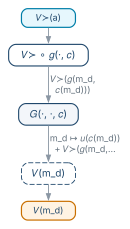

In [11]:
cons.dcsn.builder.bwd.diagram()

`checkout.explore` shows the stage's whole backward builders graph in [Google's Model Explorer](https://github.com/google-ai-edge/model-explorer), an interactive viewer in which each builder is a frame opened to the operations it holds, the decision builder drawn above among them, and in which selecting an operation shows, in a side panel, its kernel, its method once one is bound, and the wires it reads and writes, each with its perch and its type. The drawing above is the picture saved with the lesson, since the view opens only when the lesson is run: the saved output of the next cell is the paths of the two files it writes into the folder `model-explorer` beside the lesson.

In [12]:
checkout.explore(cons)

tutorials/getting-started/model-explorer/cons.graph.json
tutorials/getting-started/model-explorer/cons.edge-overlays.json


## The arrival builder

The arrival builder, `cons.arvl.builder.bwd`, the builder of the block `dcsn_to_arvl`, computes $V_\prec$ from $V$. Its signature reads the decision value, a function of resources, and writes the arrival value, a function of resources and of `l`. The file declares the value on arrival real, excluding the $-\infty$ that $V$ admits; since $V_\prec = V$, this declaration is a condition, which the card below lists under `Conditions`, assumed and not verified.

In [13]:
cons.arvl.builder.bwd.signature()

in         𝑉 : Xm → [−∞, ∞)
out        𝑉≺ : Xm × ℝ₊ → ℝ

Unlike the decision builder's card in the prerequisite lesson, which names the rule under `At`, this builder's card has no `At` heading, because the arrival law of motion involves no control. `Operations` lists the pullback along the arrival law of motion $g_\prec$, the aggregation and the evaluation.

In [14]:
cons.arvl.builder.bwd.denote()

STAGE cons / BACKWARD BUILDER dcsn → arvl (dcsn_to_arvl)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Signature
  in   𝑉   : Xm → [−∞, ∞)
       ────────────────────────────────────────────
  out  𝑉≺  : Xm × ℝ₊ → ℝ

Operations
  1  Pullback
     in: 𝑉                              out: 𝑉 ∘ 𝑔≺
     ──────────────────────────────────────────────
     rule: (𝑉 ∘ 𝑔≺)(m, l) = 𝑉(𝑔≺(m, l))

  2  Aggregation
     in: (1)                            out: 𝑉≺
     ──────────────────────────────────────────────
     rule: 𝑉≺ = 𝑉(𝑔≺(m, l))                                on (m, l) ∈ Xm × ℝ₊

  3  Evaluation
     in: 𝑉≺                             out: 𝑉≺
     ──────────────────────────────────────────────
     rule: 𝑉≺ : Xm × ℝ₊ → ℝ

Conditions
  Aggregation  𝑉≺(m, l) ∈ ℝ
──────────────────────────────────────────────────────────────────────────────
Source  cons.bl
  26  V[<] = V  :: [id=value]

Definitions referenced
  Xm    cons:set:Xm
  𝑔≺    cons:g:arvl_to_dcsn
━━

The pullback's kernel is the arrival law of motion, which the forward block `arvl_to_dcsn` states: resources on arrival are resources at the decision.

In [15]:
cons.arvl.builder.bwd["Pullback"].kernel()

𝑔 of arvl_to_dcsn: 𝑔(m, l) = m
unused l

The aggregation's kernel returns the value unchanged and uses neither resources nor `l`.

In [16]:
cons.arvl.builder.bwd["Aggregation"].kernel()

𝐺 of dcsn_to_arvl: 𝐺(V, m, l) = V
output V; unused m, l

The file states no derivative at arrival. By the chain rule, the derivative of $V_\prec$ in resources is $D_{\mathrm m_d}V(g_\prec(\mathrm m, \mathrm l))$ times the derivative of $g_\prec$ in $\mathrm m$, which equals $D_{\mathrm m_d}V(\mathrm m)$ because $g_\prec$ returns $\mathrm m$; since the package differentiates nothing, a stage with another arrival law of motion states that product by a derivative line of its own, such as `D_{m}V[<] = …`. Composed, the two builders give the arrival value at a rule $c$: $V_\prec(\mathrm m, \mathrm l) = u(c(\mathrm m)) + V_\succ(\mathrm m - c(\mathrm m))$.